# Assignment 8: Dimensionality Reduction – PCA, Kernel PCA, Sparse PCA and ICA

## Introduction
In this assignment I apply four dimensionality reduction techniques from Lesson 8 to four different datasets. Dimensionality reduction takes data with many features and represents it with only a few new features (components), while keeping as much of the important information as possible. This helps to visualize high-dimensional data, find hidden structure, and discover the basic building blocks that the data is made of.

Each technique is applied to the dataset that best shows what it is good at:
- PCA on the Wine dataset (178 wines, 13 chemical features, 3 grape cultivars): can the wines be summarized in 2 or 3 components, and do the cultivars separate?
- Kernel PCA on the Breast Cancer Wisconsin dataset (569 patients, 30 cell nucleus measurements, malignant or benign): does a non-linear projection separate the two diagnoses better than standard PCA?
- Sparse PCA on the Digits dataset (1,797 images of handwritten digits, 8 × 8 pixels): what simple, local stroke patterns are the digits made of, compared with standard PCA?
- ICA on the Olivetti Faces dataset (400 photos of 40 people, 64 × 64 pixels): what independent facial features can the faces be separated into, compared with PCA eigenfaces?

The class labels (cultivar, diagnosis, digit and person) are not used to fit any model. I only use them to colour the plots and to check how well the reduced data keeps the structure of the original data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import loadmat
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA, SparsePCA, FastICA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import silhouette_score

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Datasets

### 2.1 Wine Dataset

In [2]:
wine_cols = ["cultivar", "alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
             "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
             "color_intensity", "hue", "od280_od315", "proline"]
wine_df = pd.read_csv("wine.data", header=None, names=wine_cols)

print("Wine:", wine_df.shape)
print("Classes:", wine_df["cultivar"].value_counts().sort_index().to_dict())
print("Missing values:", wine_df.isna().sum().sum())
display(wine_df.head())

Wine: (178, 14)
Classes: {1: 59, 2: 71, 3: 48}
Missing values: 0


,cultivar,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### Interpretation – Wine Dataset
- The Wine dataset has 178 wines and 14 columns: the cultivar (grape type 1, 2 or 3) and 13 chemical measurements, such as alcohol, malic acid, flavanoids, colour intensity and proline.
- The classes are fairly balanced: 59 wines of cultivar 1, 71 of cultivar 2 and 48 of cultivar 3.
- There are no missing values.
- The features have very different scales. For example, magnesium is around 100 and proline is around 1,000, while hue is around 1. Because PCA follows variance, I need to standardize the features first, otherwise proline would dominate the components.

### 2.2 Breast Cancer Wisconsin Dataset

In [3]:
base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
        "concavity", "concave_points", "symmetry", "fractal_dimension"]
wdbc_cols = ["id", "diagnosis"] + [f"{f}_{s}" for s in ["mean", "se", "worst"] for f in base]
wdbc_df = pd.read_csv("wdbc.data", header=None, names=wdbc_cols).drop(columns="id")

print("Breast cancer:", wdbc_df.shape)
print("Classes:", wdbc_df["diagnosis"].value_counts().to_dict())
print("Missing values:", wdbc_df.isna().sum().sum())
display(wdbc_df.head())

Breast cancer: (569, 31)
Classes: {'B': 357, 'M': 212}
Missing values: 0


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Interpretation – Breast Cancer Wisconsin Dataset
- After removing the ID column, the dataset has 569 patients and 31 columns: the diagnosis and 30 measurements of cell nuclei from breast tissue images.
- The 30 features are 10 measurements (such as radius, texture, area, smoothness and concavity) recorded three ways: the mean, the standard error (se) and the worst (largest) value.
- There are 357 benign (B) and 212 malignant (M) cases, so the classes are somewhat imbalanced (63% vs 37%).
- There are no missing values. The scales are very different (for example, area_mean is around 400 to 1,300 while smoothness_mean is around 0.1), so I will standardize the features before Kernel PCA.

### 2.3 Digits Dataset

Digits: (1797, 64)
Pixel range: 0.0 to 16.0
Images per digit: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


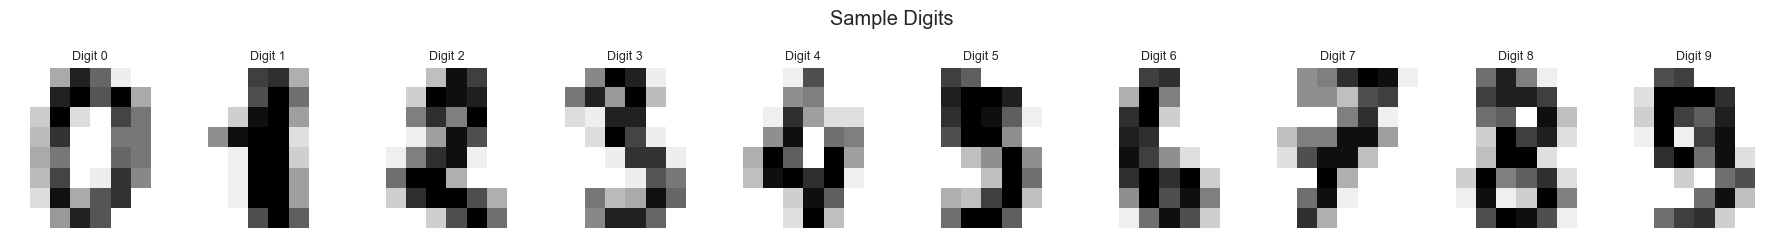

In [4]:
digits = load_digits()

print("Digits:", digits.data.shape)
print("Pixel range:", digits.data.min(), "to", digits.data.max())
print("Images per digit:", np.bincount(digits.target).tolist())

fig, axes = plt.subplots(1, 10, figsize=(18, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"Digit {digits.target[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample Digits")
plt.tight_layout(); plt.show()

### Interpretation – Digits Dataset
- The Digits dataset has 1,797 images of handwritten digits. Each image is 8 × 8 pixels, giving 64 features per image.
- Pixel values range from 0 (white) to 16 (full ink).
- The 10 digits are almost perfectly balanced, with between 174 and 183 images each.
- The images are low resolution, but each digit is still recognizable from its strokes. Sparse PCA should find simple, local stroke patterns that combine to form these digits.

### 2.4 Olivetti Faces Dataset

Faces: (400, 4096) | image size: (64, 64)
Pixel range: 0.0 to 0.95


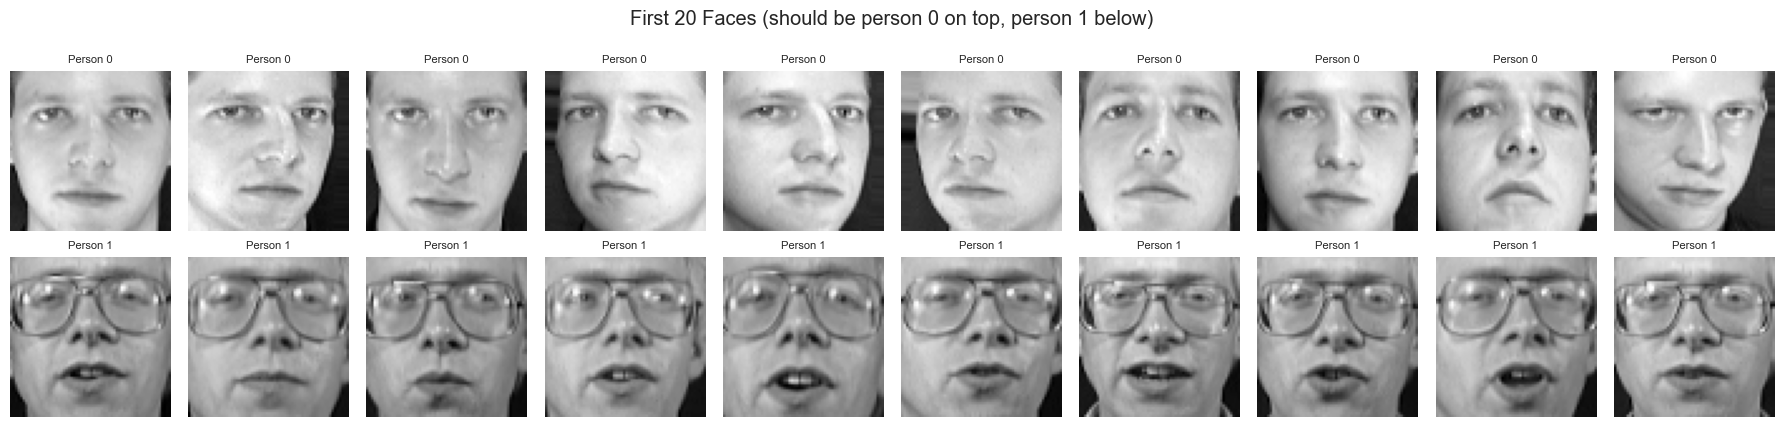

In [5]:
mat = loadmat("olivettifaces.mat")
faces_img = (mat["faces"].T.astype("float64") / 255.0).reshape(-1, 64, 64).transpose(0, 2, 1)
X_faces = faces_img.reshape(len(faces_img), -1)
faces_person = np.repeat(np.arange(40), 10)

print("Faces:", X_faces.shape, "| image size:", faces_img.shape[1:])
print("Pixel range:", round(X_faces.min(), 2), "to", round(X_faces.max(), 2))

fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))
for row in range(2):
    for col in range(10):
        idx = row * 10 + col
        axes[row, col].imshow(faces_img[idx], cmap="gray")
        axes[row, col].set_title(f"Person {faces_person[idx]}", fontsize=8)
        axes[row, col].axis("off")
plt.suptitle("First 20 Faces (should be person 0 on top, person 1 below)")
plt.tight_layout(); plt.show()

### Interpretation – Olivetti Faces Dataset
- The Olivetti dataset has 400 grayscale face images of 40 people (10 images per person). Each image is 64 × 64 pixels, giving 4,096 features per image. I scaled the pixels to the range 0 to 1.
- The file stores the images as columns and saves them column by column (MATLAB format), so I transposed the data and swapped the rows and columns of each image to get upright faces.
- The file has no labels, but the images are stored in order, so images 0 to 9 belong to person 0, images 10 to 19 to person 1, and so on. The plot confirms this: the top row shows the same man in all 10 images, and the bottom row shows another man with glasses in all 10 images.
- Each person's photos differ in head angle, facial expression and lighting. These variations are the kind of independent factors that ICA can try to separate.
- With 4,096 features but only 400 images, this dataset has many more features than samples, which makes dimensionality reduction especially useful.

## 3. Task 1 – PCA on the Wine Dataset

  PC  explained_%  cumulative_%
 PC1         36.2          36.2
 PC2         19.2          55.4
 PC3         11.1          66.5
 PC4          7.1          73.6
 PC5          6.6          80.2
 PC6          4.9          85.1
 PC7          4.2          89.3
 PC8          2.7          92.0
 PC9          2.2          94.2
PC10          1.9          96.2
PC11          1.7          97.9
PC12          1.3          99.2
PC13          0.8         100.0


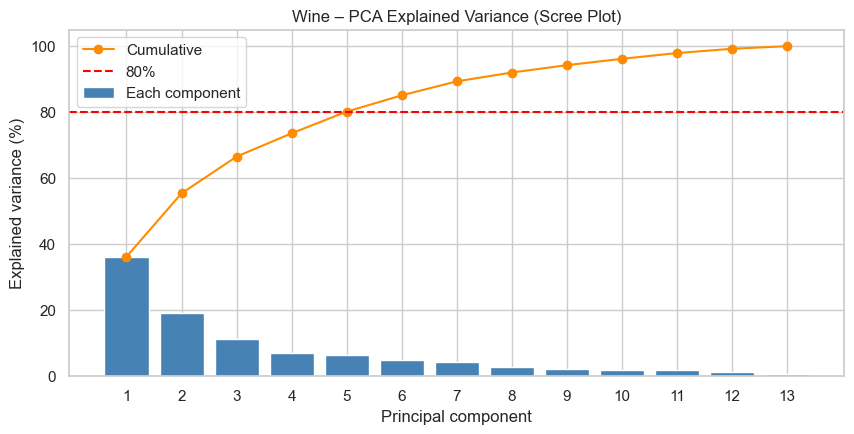

In [6]:
X_wine = wine_df.drop(columns="cultivar")
y_wine = wine_df["cultivar"].values
X_wine_scaled = StandardScaler().fit_transform(X_wine)

pca_wine_full = PCA(random_state=42).fit(X_wine_scaled)
evr = pca_wine_full.explained_variance_ratio_
cum = np.cumsum(evr)
print(pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))],
                    "explained_%": (evr * 100).round(1),
                    "cumulative_%": (cum * 100).round(1)}).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, 14), evr * 100, color="steelblue", label="Each component")
ax.plot(range(1, 14), cum * 100, marker="o", color="darkorange", label="Cumulative")
ax.axhline(80, color="red", linestyle="--", label="80%")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance (%)")
ax.set_title("Wine – PCA Explained Variance (Scree Plot)")
ax.set_xticks(range(1, 14)); ax.legend()
plt.show()

## 2D projection, loadings and separation check

Loadings (how much each feature contributes to each component):


,PC1,PC2
nonflavanoid_phenols,-0.299,0.029
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
color_intensity,-0.089,0.530
ash,-0.002,0.316
magnesium,0.142,0.300
alcohol,0.144,0.484
proline,0.287,0.365
hue,0.297,-0.279
proanthocyanins,0.313,0.039


5-fold accuracy – all 13 features: 0.989 | only 2 PCs: 0.955
Silhouette of cultivars – original 13D: 0.280 | 2 PCs: 0.526


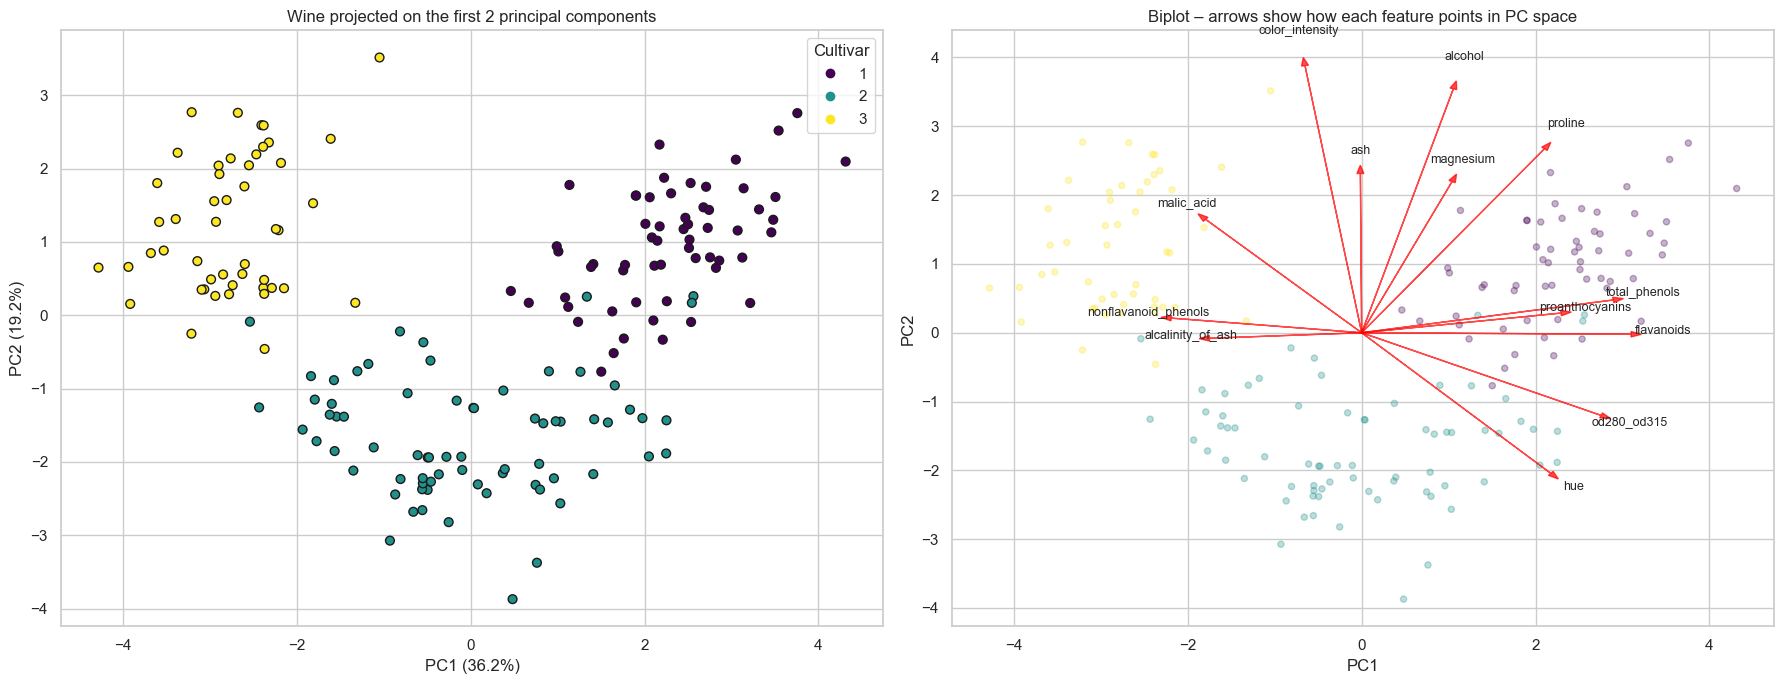

In [7]:
pca_wine = PCA(n_components=2, random_state=42)
Z_wine = pca_wine.fit_transform(X_wine_scaled)

loadings = pd.DataFrame(pca_wine.components_.T, index=X_wine.columns, columns=["PC1", "PC2"]).round(3)
print("Loadings (how much each feature contributes to each component):")
display(loadings.sort_values("PC1"))

acc_all = cross_val_score(LogisticRegression(max_iter=1000), X_wine_scaled, y_wine, cv=5).mean()
acc_2pc = cross_val_score(LogisticRegression(max_iter=1000), Z_wine, y_wine, cv=5).mean()
print(f"5-fold accuracy – all 13 features: {acc_all:.3f} | only 2 PCs: {acc_2pc:.3f}")
print(f"Silhouette of cultivars – original 13D: {silhouette_score(X_wine_scaled, y_wine):.3f} | "
      f"2 PCs: {silhouette_score(Z_wine, y_wine):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sc = axes[0].scatter(Z_wine[:, 0], Z_wine[:, 1], c=y_wine, cmap="viridis", s=40, edgecolor="k")
axes[0].legend(*sc.legend_elements(), title="Cultivar")
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); axes[0].set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
axes[0].set_title("Wine projected on the first 2 principal components")

axes[1].scatter(Z_wine[:, 0], Z_wine[:, 1], c=y_wine, cmap="viridis", s=20, alpha=0.3)
scale = np.abs(Z_wine).max() / np.abs(loadings.values).max() * 0.9
for feat, (l1, l2) in loadings.iterrows():
    axes[1].arrow(0, 0, l1 * scale, l2 * scale, color="red", alpha=0.7, head_width=0.08)
    axes[1].text(l1 * scale * 1.12, l2 * scale * 1.12, feat, fontsize=9, ha="center")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Biplot – arrows show how each feature points in PC space")
plt.tight_layout(); plt.show()

## Task 1 – PCA on the Wine Dataset

### Explained variance
- I standardized the 13 chemical features and applied PCA. PC1 explains 36.2% of the variance and PC2 explains 19.2%, so the first two components together keep 55.4% of the information.
- Five components are needed to reach 80% (80.2%) and eight to reach 92%. The scree plot shows an elbow around the third component, after which each component adds less than about 7%, so the first few components capture most of the important structure.

### What the components mean
- PC1 is mainly a "phenol richness" axis. It has large positive loadings for flavanoids (0.42), total phenols (0.40), OD280/OD315 (0.38) and proanthocyanins (0.31), and negative loadings for nonflavanoid phenols (-0.30), malic acid (-0.25) and alcalinity of ash (-0.24). Wines with a high PC1 score are rich in flavanoids and phenols.
- PC2 is mainly a "strength and colour" axis. It has large positive loadings for colour intensity (0.53), alcohol (0.48), proline (0.37), ash and magnesium, and a negative loading for hue (-0.28). Wines with a high PC2 score are stronger and darker.

### Separation of the cultivars
- In the 2D plot, the three cultivars form three clear groups, even though PCA never used the labels:
  - Cultivar 1 is on the right and top: rich in phenols, with high alcohol and proline.
  - Cultivar 3 is on the left and top: low in phenols, with high colour intensity and malic acid.
  - Cultivar 2 is at the bottom in the middle: lower alcohol and colour intensity and a higher hue, so a lighter wine.
- There is only a small overlap between cultivar 2 and the other two.
- The biplot confirms this: the flavanoid, total phenol and proanthocyanin arrows point towards cultivar 1, the malic acid, nonflavanoid phenol and alcalinity arrows point towards cultivar 3, colour intensity and alcohol point upwards, and hue points down to the right.

### How much information was kept
- A simple logistic regression classifier reached 98.9% accuracy with all 13 features and 95.5% with only the 2 principal components. Reducing the data from 13 to 2 dimensions lost only 3.4 percentage points of accuracy.
- The silhouette score of the cultivars is actually higher in the 2D PCA space (0.526) than in the original 13 dimensions (0.280). The remaining components mostly contain small, noisy variation that blurs the groups, so keeping only the strongest directions makes the cultivars stand out more clearly.
- Overall, PCA works very well on the Wine data: two components are enough to visualize and separate the three cultivars, and the loadings show which chemical properties define each one.

## 4. Task 2 – Kernel PCA on the Breast Cancer Wisconsin Dataset

                         method  accuracy_2_components  silhouette
                     Linear PCA                  0.953       0.438
Kernel PCA (RBF, gamma = 0.005)                  0.933       0.457
 Kernel PCA (RBF, gamma = 0.03)                  0.935       0.437
  Kernel PCA (RBF, gamma = 0.1)                  0.865       0.267
  Kernel PCA (RBF, gamma = 0.5)                  0.627       0.015
    Kernel PCA (poly, degree 3)                  0.874       0.331
    All 30 features (reference)                  0.981       0.294


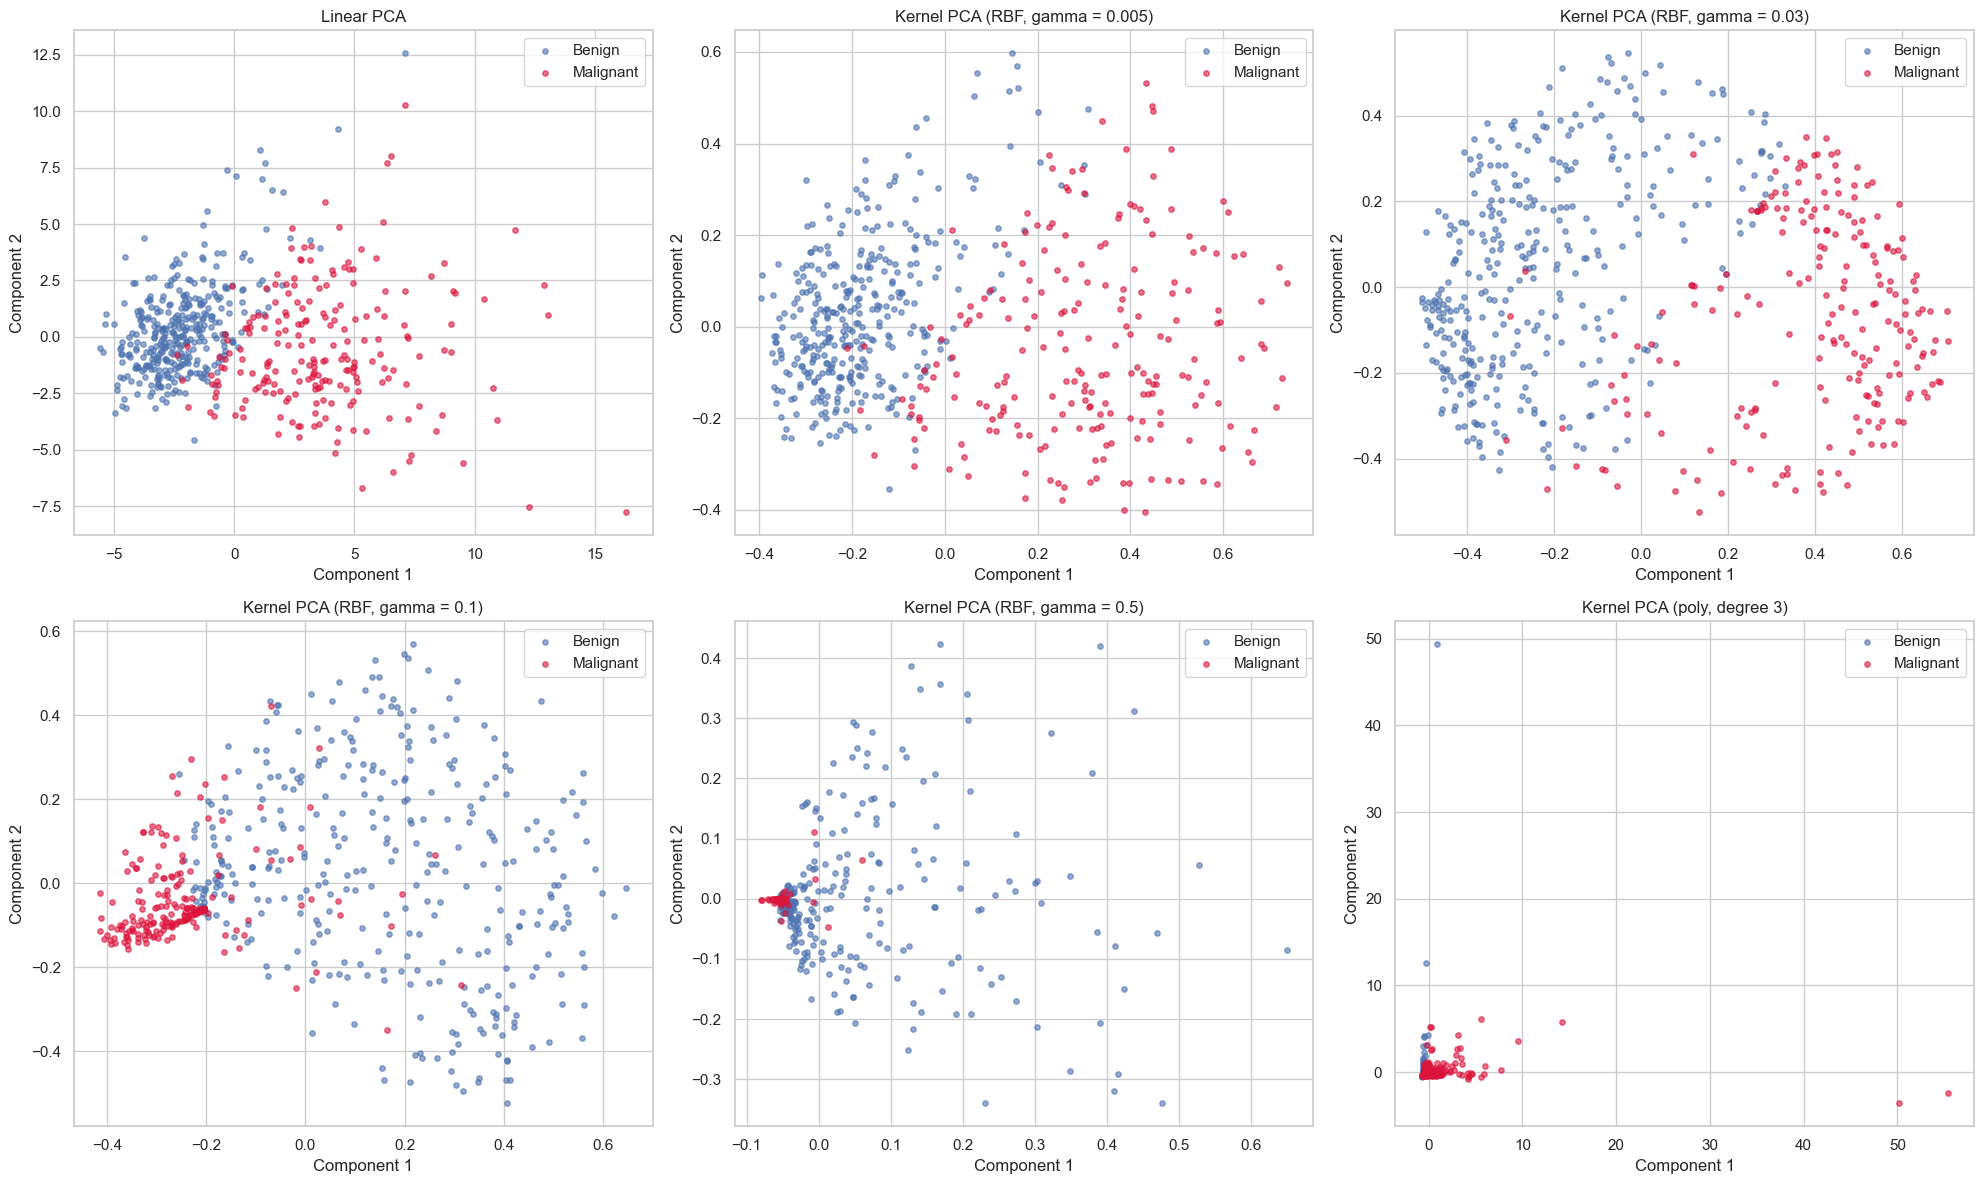

In [8]:
X_bc = wdbc_df.drop(columns="diagnosis")
y_bc = (wdbc_df["diagnosis"] == "M").astype(int).values
X_bc_scaled = StandardScaler().fit_transform(X_bc)

settings = [("Linear PCA", PCA(n_components=2, random_state=42))] + [
    (f"Kernel PCA (RBF, gamma = {g})", KernelPCA(n_components=2, kernel="rbf", gamma=g, random_state=42))
    for g in [0.005, 0.03, 0.1, 0.5]] + [
    ("Kernel PCA (poly, degree 3)", KernelPCA(n_components=2, kernel="poly", degree=3, random_state=42))]

rows, projections = [], {}
for name, model in settings:
    Z = model.fit_transform(X_bc_scaled)
    projections[name] = Z
    rows.append({"method": name,
                 "accuracy_2_components": round(cross_val_score(LogisticRegression(max_iter=1000), Z, y_bc, cv=5).mean(), 3),
                 "silhouette": round(silhouette_score(Z, y_bc), 3)})
rows.append({"method": "All 30 features (reference)",
             "accuracy_2_components": round(cross_val_score(LogisticRegression(max_iter=1000), X_bc_scaled, y_bc, cv=5).mean(), 3),
             "silhouette": round(silhouette_score(X_bc_scaled, y_bc), 3)})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, (name, Z) in zip(axes.flatten(), projections.items()):
    ax.scatter(Z[y_bc == 0, 0], Z[y_bc == 0, 1], s=15, alpha=0.6, label="Benign")
    ax.scatter(Z[y_bc == 1, 0], Z[y_bc == 1, 1], s=15, alpha=0.6, color="crimson", label="Malignant")
    ax.set_title(name); ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2"); ax.legend()
plt.tight_layout(); plt.show()

## Task 2 – Kernel PCA on the Breast Cancer Wisconsin Dataset
- I standardized the 30 features and compared linear PCA with Kernel PCA using an RBF kernel (gamma = 0.005, 0.03, 0.1 and 0.5) and a polynomial kernel (degree 3), each reduced to 2 components. To compare them fairly, I measured how well a simple classifier separates benign and malignant cases using only the 2 components, and the silhouette score of the two diagnoses.

### Results
- Linear PCA gave the best accuracy (95.3%) with a silhouette of 0.438. In the plot, benign cases form a tight cloud on the left and malignant cases spread out to the right, so the first component already separates the two diagnoses well.
- Kernel PCA with a small gamma (0.005 and 0.03) gave very similar results: accuracy of 93.3% to 93.5% and silhouettes of 0.457 and 0.437. With a small gamma, the RBF kernel behaves almost like linear PCA, and the plots look almost the same.
- With gamma = 0.1, accuracy dropped to 86.5%. The malignant cases were squeezed into a curved strip while the benign cases spread out.
- With gamma = 0.5, the projection collapsed: almost all points were crushed together, accuracy fell to 62.7% (exactly the share of benign cases, so no better than predicting "benign" for everyone) and the silhouette was close to 0. When gamma is too large, the kernel becomes so local that every patient only looks similar to itself, so there is no useful structure left.
- The polynomial kernel reached 87.4%. A few extreme patients were stretched far away (up to about 50 on the first component), which squeezed all the other patients into a small corner.
- For reference, a classifier using all 30 features reached 98.1%, so 2 linear components keep most of the useful information.

### Discussion
- On this dataset, Kernel PCA did not improve on linear PCA. The difference between benign and malignant tumours is mostly linear: malignant cells are simply larger and more irregular (larger radius, area and concavity), which is a straight direction that linear PCA already captures.
- Kernel PCA is most useful when the data has curved, non-linear structure, such as the two half-moons example from Lesson 8, where linear PCA cannot separate the groups.
- The results show that the choice of kernel and gamma is critical: a small gamma gives results similar to linear PCA, while a large gamma destroys the structure.
- Kernel PCA also has practical downsides: its components cannot be interpreted with loadings like in linear PCA, and it needs a kernel matrix of size 569 × 569, which becomes expensive for large datasets.

## 5. Task 3 – Sparse PCA on the Digits Dataset

      alpha  zero_weights_%  avg_pixels_per_component  reconstruction_MSE
        0.1            45.6                      34.8              0.0111
        0.5            71.9                      18.0              0.0121
        1.0            83.0                      10.9              0.0139
        2.0            91.9                       5.2              0.0167
PCA (dense)             4.7                      64.0              0.0110


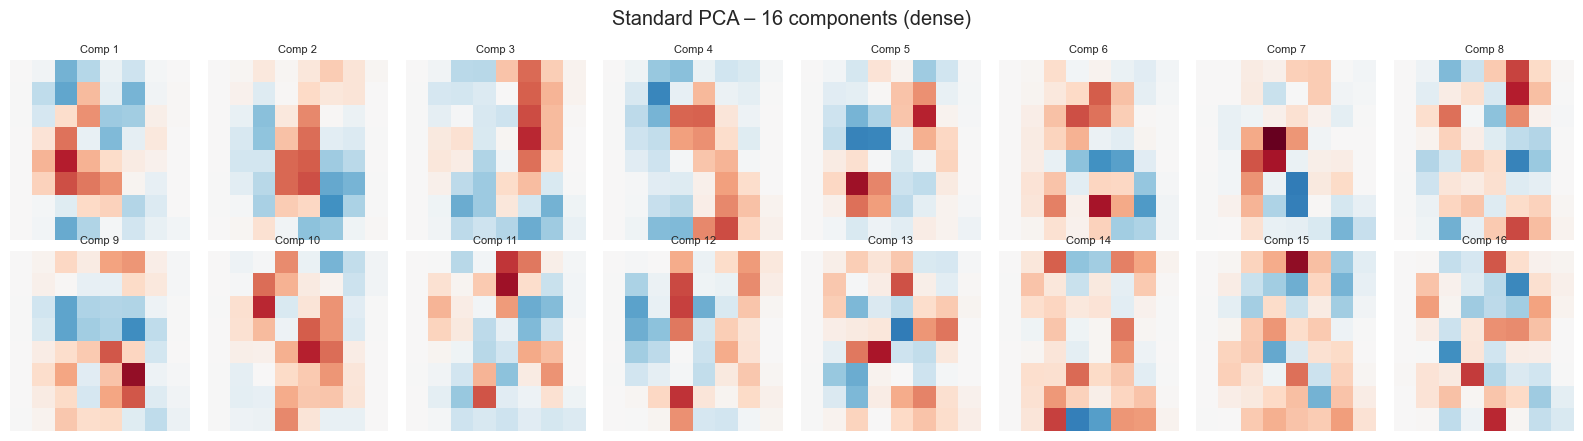

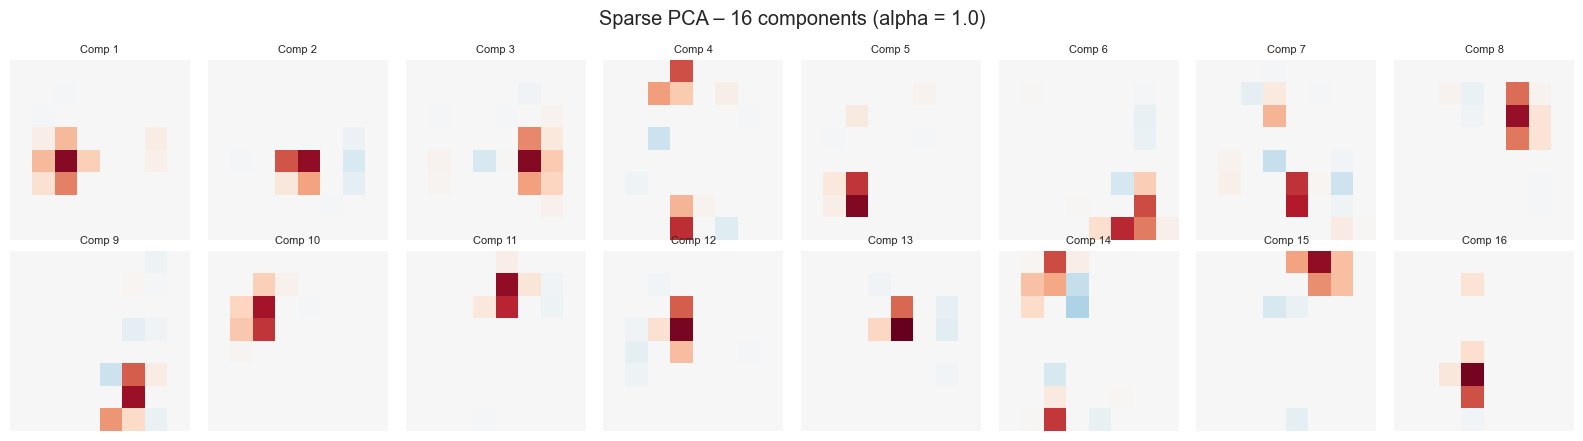

In [9]:
X_digits = digits.data / 16.0
n_comp = 16

pca_dig = PCA(n_components=n_comp, random_state=42).fit(X_digits)

alpha_rows = []
spca_models = {}
for alpha in [0.1, 0.5, 1.0, 2.0]:
    spca = SparsePCA(n_components=n_comp, alpha=alpha, random_state=42, max_iter=500).fit(X_digits)
    spca_models[alpha] = spca
    recon = spca.inverse_transform(spca.transform(X_digits))
    alpha_rows.append({"alpha": alpha,
                       "zero_weights_%": round((spca.components_ == 0).mean() * 100, 1),
                       "avg_pixels_per_component": round((spca.components_ != 0).sum(axis=1).mean(), 1),
                       "reconstruction_MSE": round(np.mean((X_digits - recon) ** 2), 4)})
pca_recon = pca_dig.inverse_transform(pca_dig.transform(X_digits))
alpha_rows.append({"alpha": "PCA (dense)",
                   "zero_weights_%": round((np.abs(pca_dig.components_) < 1e-10).mean() * 100, 1),
                   "avg_pixels_per_component": 64.0,
                   "reconstruction_MSE": round(np.mean((X_digits - pca_recon) ** 2), 4)})
print(pd.DataFrame(alpha_rows).to_string(index=False))

def show_components(comps, title):
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    lim = np.abs(comps).max()
    for i, ax in enumerate(axes.flatten()):
        ax.imshow(comps[i].reshape(8, 8), cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"Comp {i+1}", fontsize=8)
        ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_components(pca_dig.components_, "Standard PCA – 16 components (dense)")
show_components(spca_models[1.0].components_, "Sparse PCA – 16 components (alpha = 1.0)")

## Task 3 – Sparse PCA on the Digits Dataset
- I scaled the pixels to the range 0 to 1 and reduced the 64 pixels to 16 components with standard PCA and with Sparse PCA, using four values of the sparsity parameter alpha (0.1, 0.5, 1.0 and 2.0).

### Effect of alpha
- Standard PCA is dense: almost every component uses all 64 pixels. Its only zero weights (4.7%) come from the few border pixels that are blank in every image. Its reconstruction error is 0.0110.
- With alpha = 0.1, 45.6% of the weights became exactly 0 (each component uses about 35 pixels), while the reconstruction error stayed almost the same (0.0111). So a small amount of sparsity costs almost nothing.
- As alpha increases, the components get sparser but lose more information: with alpha = 0.5, 71.9% zeros (18 pixels per component, error 0.0121); with alpha = 1.0, 83.0% zeros (about 11 pixels, error 0.0139); and with alpha = 2.0, 91.9% zeros (about 5 pixels, error 0.0167, about 52% higher than PCA).
- This shows the trade-off: more sparsity gives simpler and more interpretable components, but each component carries less information, so the images are rebuilt less accurately.

### Comparing the components
- The standard PCA components are whole-image patterns. Each one mixes positive (red) and negative (blue) weights across the entire 8 × 8 image, so they look like ghostly contrasts between different digit shapes and are hard to interpret.
- The Sparse PCA components (alpha = 1.0) are small, local blobs of only a few pixels, with the rest of the image at exactly 0. Each one looks like a single stroke or segment in one location: some capture the top bar (for example, components 4 and 15), some the centre of the digit (components 1, 2, 3, 12 and 13), some the bottom (components 5, 9 and 16), and some the left or right sides (components 6, 8 and 10).
- Most sparse weights are positive, so the components act like building blocks that are added together, similar to the segments of a digital clock display. A digit can be described as a combination of a few strokes, such as a top bar, a centre stroke and a bottom curve.
- Overall, Sparse PCA gives much more interpretable components than standard PCA, at the cost of a slightly higher reconstruction error. This matches Lesson 8: sparse PCA and dictionary learning find "atoms" that can be combined to build each sample.

## 6. Task 4 – ICA on the Olivetti Faces Dataset

In [11]:
from scipy.stats import kurtosis

n_ic = 50
pca_faces = PCA(n_components=n_ic, whiten=False, random_state=42).fit(X_faces)
ica = FastICA(n_components=n_ic, whiten="unit-variance", fun="logcosh", max_iter=2000, random_state=42)
S_ica = ica.fit_transform(X_faces)
S_pca = pca_faces.transform(X_faces)

ica_comps = ica.components_ * np.sign(ica.components_[np.arange(n_ic), np.abs(ica.components_).argmax(axis=1)])[:, None]
order = np.argsort(-kurtosis(S_ica, axis=0))
print(f"PCA: {n_ic} components keep {pca_faces.explained_variance_ratio_.sum()*100:.1f}% of the variance")
print(f"Average kurtosis of component scores – PCA: {kurtosis(S_pca, axis=0).mean():.2f} | "
      f"ICA: {kurtosis(S_ica, axis=0).mean():.2f}")

rec_pca = pca_faces.inverse_transform(S_pca)
rec_ica = ica.inverse_transform(S_ica)
print(f"Reconstruction MSE – PCA: {np.mean((X_faces - rec_pca)**2):.5f} | ICA: {np.mean((X_faces - rec_ica)**2):.5f}")



PCA: 50 components keep 87.3% of the variance
Average kurtosis of component scores – PCA: 0.20 | ICA: 16.57
Reconstruction MSE – PCA: 0.00220 | ICA: 0.00219


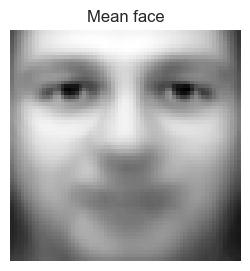

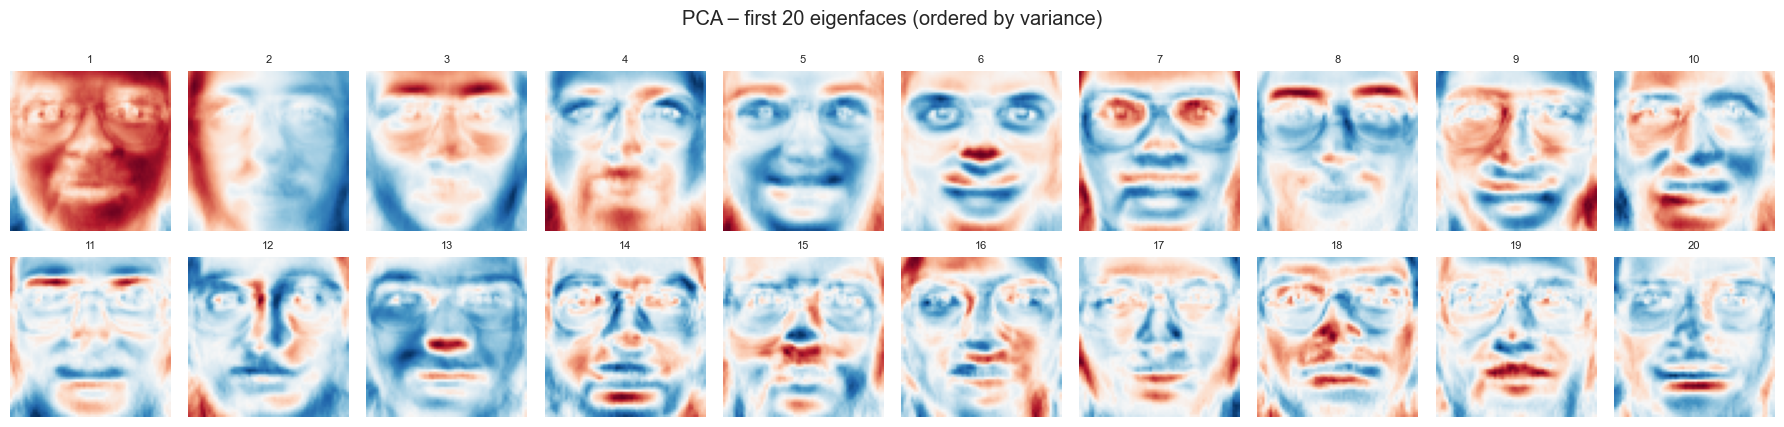

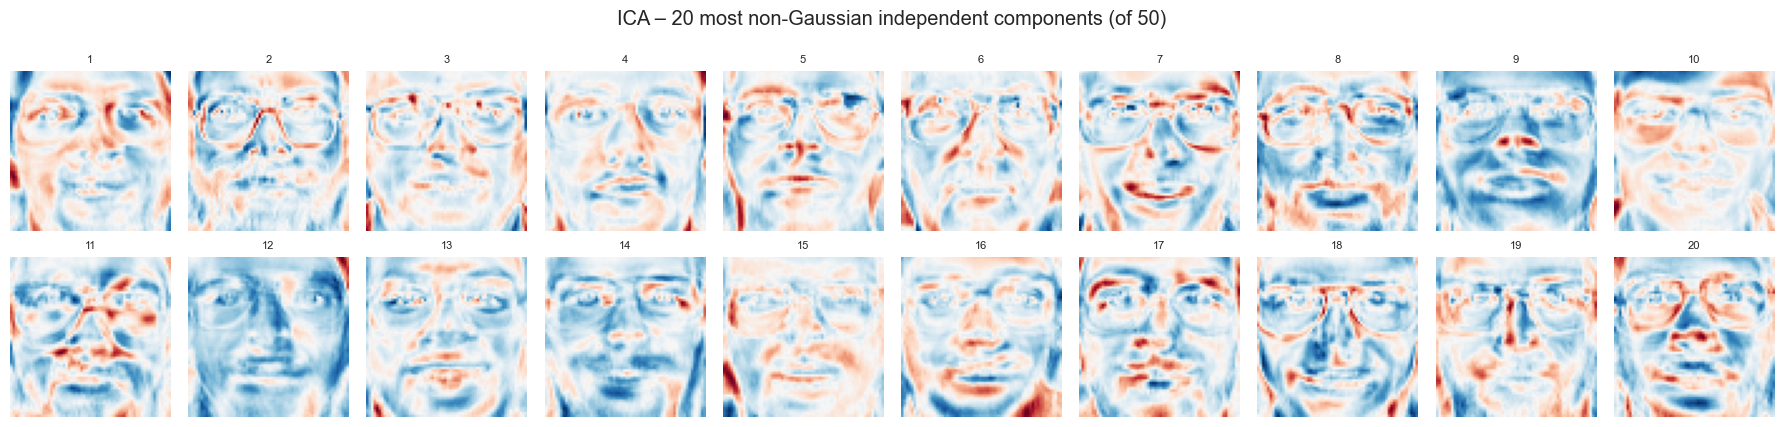

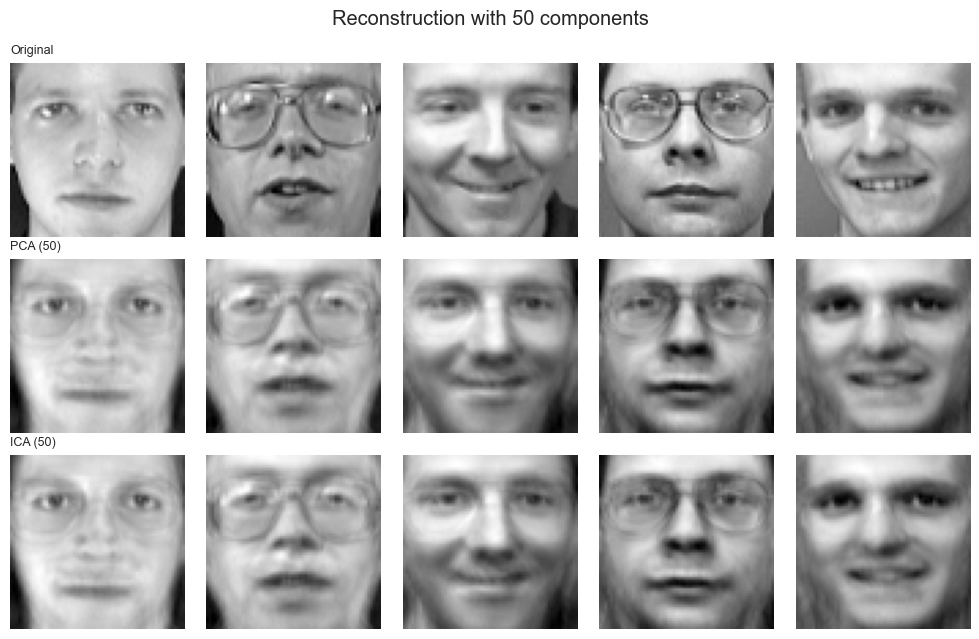

In [12]:
def show_faces(imgs, title, n=20, cmap="gray"):
    fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))
    for i, ax in enumerate(axes.flatten()[:n]):
        ax.imshow(imgs[i].reshape(64, 64), cmap=cmap)
        ax.set_title(f"{i+1}", fontsize=8); ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(pca_faces.mean_.reshape(64, 64), cmap="gray"); ax.set_title("Mean face"); ax.axis("off"); plt.show()
show_faces(pca_faces.components_, "PCA – first 20 eigenfaces (ordered by variance)", cmap="RdBu_r")
show_faces(ica_comps[order], "ICA – 20 most non-Gaussian independent components (of 50)", cmap="RdBu_r")

idx = [0, 10, 20, 30, 40]
fig, axes = plt.subplots(3, 5, figsize=(10, 6.5))
for col, i in enumerate(idx):
    for row, (img, lab) in enumerate([(X_faces[i], "Original"), (rec_pca[i], "PCA (50)"), (rec_ica[i], "ICA (50)")]):
        axes[row, col].imshow(img.reshape(64, 64), cmap="gray"); axes[row, col].axis("off")
        if col == 0: axes[row, col].set_title(lab, fontsize=9, loc="left")
plt.suptitle("Reconstruction with 50 components"); plt.tight_layout(); plt.show()

## Task 4 – ICA on the Olivetti Faces Dataset
- I applied FastICA with 50 components to the 400 face images (4,096 pixels each) and compared it with PCA using the same number of components. FastICA first centres and whitens the data, then rotates the components to make them as statistically independent (non-Gaussian) as possible.
- With 50 components, PCA keeps 87.3% of the variance, so each face is compressed from 4,096 pixel values to 50 numbers while keeping most of the information.

### Independence (kurtosis)
- The average kurtosis of the component scores is 0.20 for PCA (close to a Gaussian distribution) and 16.57 for ICA (very non-Gaussian). This shows that ICA achieved its goal of finding non-Gaussian, independent components.
- A high kurtosis means each ICA component is used strongly by only a few faces and very little by the others. So each ICA component tends to capture something specific, such as the glasses or face shape of particular people. In contrast, PCA components are used a little by every face.

### Reconstruction
- The reconstruction error is almost identical for PCA (0.00220) and ICA (0.00219). With the same number of components, ICA only rotates the 50-dimensional space found by PCA into a different set of axes, so the same information is kept. The difference is in the building blocks, not in how much information is preserved.
- The reconstructed faces are clearly recognizable but blurrier than the originals, because fine details are lost. Person 0, who does not wear glasses, shows a faint ghost of glasses in the reconstruction, because glasses are a common pattern captured by the shared components.

### Comparing the components
- The mean face is a blurry average showing the typical positions of the eyes, nose and mouth.
- The PCA eigenfaces are global, whole-face patterns ordered by variance. The first components mainly capture lighting: overall brightness (component 1), left versus right lighting (component 2) and top versus bottom lighting (component 3). Later components capture glasses (for example, components 7, 8 and 10) and mouth or expression changes (components 5, 6 and 13).
- The ICA components look more local and edge-like. They focus on specific facial features, such as the eyes, glasses frames, eyebrows, nose edges and mouth lines, and several look like the features of one particular person. They depend less on global lighting.
- Overall, PCA describes faces as the mean face plus a few global variations (mainly lighting and overall shape), while ICA describes them as a combination of more independent, localized features. This matches Lesson 8: ICA separates data into independent sources, which is useful for finding separate visual elements.

## 7. Comparison of the Techniques and Conclusion

### Summary of results
- PCA (Wine): two components kept 55.4% of the variance and clearly separated the three cultivars. A simple classifier reached 95.5% accuracy with only 2 components (versus 98.9% with all 13 features), and the loadings showed that PC1 represents phenol richness and PC2 represents alcohol strength and colour.
- Kernel PCA (Breast Cancer): Kernel PCA did not improve on linear PCA (95.3% accuracy with 2 linear components versus at most 93.5% with Kernel PCA), because the difference between benign and malignant tumours is mostly linear. With a large gamma (0.5), the projection collapsed completely, showing how important the kernel parameters are.
- Sparse PCA (Digits): Sparse PCA turned the dense, hard-to-read PCA components into small, local stroke patterns. With alpha = 1.0, 83% of the weights were exactly 0 (about 11 pixels per component), at the cost of a higher reconstruction error (0.0139 vs 0.0110 for PCA). With alpha = 0.1, almost half the weights were 0 with almost no loss.
- ICA (Faces): ICA found highly non-Gaussian components (average kurtosis 16.57 vs 0.20 for PCA) that focus on local features like eyes, glasses and mouth lines, while PCA eigenfaces mainly captured global lighting and shape. Both had the same reconstruction error, because ICA is a rotation of the same subspace.

### When to use each technique
- PCA: the first choice for compressing and visualizing data when the important structure is linear. It is fast, and its loadings are easy to interpret.
- Kernel PCA: useful when the data has curved, non-linear structure that PCA cannot unfold, but it needs careful tuning of the kernel and gamma, is harder to interpret and becomes expensive on large datasets.
- Sparse PCA: useful when interpretability matters, because each component uses only a few features. There is a trade-off between sparsity and reconstruction accuracy, controlled by alpha.
- ICA: useful when the data is a mix of independent sources, such as separating signals or finding independent visual features. Its components have no natural order and can come out with a flipped sign.

### Conclusion
Each technique gives a different kind of building block: PCA finds the directions of largest variance, Kernel PCA can bend around non-linear structure, Sparse PCA finds simple local parts, and ICA finds statistically independent features. The best choice depends on the structure of the data and on the goal: compression, visualization, interpretability or source separation. In this assignment, PCA worked best for the Wine and Breast Cancer data, Sparse PCA gave the most interpretable components for the digits, and ICA revealed more localized facial features than PCA for the faces.